In [1]:
#fill NA with None
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import random
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from statistics import mean

In [2]:
#https://stackoverflow.com/questions/20224526/how-to-extract-the-decision-rules-from-scikit-learn-decision-tree
def get_code(tree, feature_names):
        left      = tree.tree_.children_left
        right     = tree.tree_.children_right
        threshold = tree.tree_.threshold
        features  = [feature_names[i] for i in tree.tree_.feature]
        value = tree.tree_.value

        def recurse(left, right, threshold, features, node):
                if (threshold[node] != -2):
                        print("if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
                        if left[node] != -1:
                                recurse (left, right, threshold, features,left[node])
                        print( "} else {")
                        if right[node] != -1:
                                recurse (left, right, threshold, features,right[node])
                        print( "}")
                else:
                        print( "return " + str(value[node]))

        recurse(left, right, threshold, features, 0)

In [3]:
data = pd.read_excel('dataset_gen.xlsx') 
dataset_all_gen = pd.read_excel('dataset_all_gen.xlsx')
dataset_all_original = pd.read_excel('dataset_all_original.xlsx')
dataset_jaccard_gen = pd.read_excel('dataset_jaccard_gen.xlsx')
dataset_jaccard_original = pd.read_excel('dataset_jaccard_original.xlsx')
dataset_myroom_gen = pd.read_excel('dataset_myroom_gen.xlsx')
dataset_myroom_original = pd.read_excel('dataset_myroom_original.xlsx')
dataset_university_gen = pd.read_excel('dataset_university_gen.xlsx')
dataset_university_original = pd.read_excel('dataset_university_original.xlsx')

In [4]:
data = data.sample(frac = 1) 
dataset_all_gen = dataset_all_gen.sample(frac = 1) 
dataset_all_original = dataset_all_original.sample(frac = 1) 
dataset_jaccard_gen = dataset_jaccard_gen.sample(frac = 1) 
dataset_jaccard_original = dataset_jaccard_original.sample(frac = 1) 
dataset_myroom_gen = dataset_myroom_gen.sample(frac = 1) 
dataset_myroom_original = dataset_myroom_original.sample(frac = 1) 
dataset_university_gen = dataset_university_gen.sample(frac = 1) 
dataset_university_original = dataset_university_original.sample(frac = 1) 

In [5]:

data = data.reset_index(drop=True)
dataset_all_gen = dataset_all_gen.reset_index(drop=True)
dataset_all_original = dataset_all_original.reset_index(drop=True)
dataset_jaccard_gen = dataset_jaccard_gen.reset_index(drop=True)
dataset_jaccard_original = dataset_jaccard_original.reset_index(drop=True)
dataset_myroom_gen = dataset_myroom_gen.reset_index(drop=True)
dataset_myroom_original = dataset_myroom_original.reset_index(drop=True)
dataset_university_gen = dataset_university_gen.reset_index(drop=True)
dataset_university_original = dataset_university_original.reset_index(drop=True)

In [6]:
data.isnull().sum()

type             0
Name             0
Vendor           0
DNS           2304
mDNS          2704
NUPNP        11000
open_port     1731
SSDP_Type     2304
SSDP_t       11000
SSDP_v       11000
dtype: int64

In [7]:
data = data.fillna("NaN")

In [8]:
#fill Na
dataset_all_gen = dataset_all_gen.fillna("NaN")
dataset_all_original = dataset_all_original.fillna("NaN")
dataset_jaccard_gen = dataset_jaccard_gen.fillna("NaN")
dataset_jaccard_original = dataset_jaccard_original.fillna("NaN")
dataset_myroom_gen = dataset_myroom_gen.fillna("NaN")
dataset_myroom_original = dataset_myroom_original.fillna("NaN")
dataset_university_gen = dataset_university_gen.fillna("NaN")
dataset_university_original = dataset_university_original.fillna("NaN")

In [9]:
data.isnull().sum()

type         0
Name         0
Vendor       0
DNS          0
mDNS         0
NUPNP        0
open_port    0
SSDP_Type    0
SSDP_t       0
SSDP_v       0
dtype: int64

In [10]:
data.dtypes

type         object
Name         object
Vendor       object
DNS          object
mDNS         object
NUPNP        object
open_port    object
SSDP_Type    object
SSDP_t       object
SSDP_v       object
dtype: object

In [11]:
data = data.astype('category')

In [12]:
dataset_all_gen = dataset_all_gen.astype('category')
dataset_all_original = dataset_all_original.astype('category')
dataset_jaccard_gen = dataset_jaccard_gen.astype('category')
dataset_jaccard_original = dataset_jaccard_original.astype('category')
dataset_myroom_gen = dataset_myroom_gen.astype('category')
dataset_myroom_original = dataset_myroom_original.astype('category')
dataset_university_gen = dataset_university_gen.astype('category')
dataset_university_original = dataset_university_original.astype('category')

In [13]:
data.dtypes

type         category
Name         category
Vendor       category
DNS          category
mDNS         category
NUPNP        category
open_port    category
SSDP_Type    category
SSDP_t       category
SSDP_v       category
dtype: object

In [14]:
data

,type,Name,Vendor,DNS,mDNS,NUPNP,open_port,SSDP_Type,SSDP_t,SSDP_v
0,Appliances,Google Home,Google,xinhuanet.com,_sonsing._udp.local.,NaN,tcp/1883,NOTIFY * HTTP/1.1,NaN,NaN
1,Hubs,Caseta Wireless Hub,"Lutron Electronics Co., Inc",un.org,_andalax._udp.local.,NaN,tcp/22,NOTIFY * HTTP/1.1,NaN,NaN
2,Appliances,Chamberlain myQ Garage Opener,"The Chamberlain Group, Inc.",mac.com,_fintone._tcp.local.,NaN,tcp/80,NOTIFY * HTTP/1.1,NaN,NaN
3,Hubs,Wink 2 Hub,WINK LABS INC,si.edu,_cardify._udp.local.,NaN,tcp/443,NOTIFY * HTTP/1.1,NaN,NaN
4,Cameras,August Doorbell Cam,August Home,nasa.gov,NaN,NaN,tcp/1900,NOTIFY * HTTP/1.1,NaN,NaN
5,Cameras,Piper NV,"Icontrol Networks Canada, Inc",vimeo.com,_rank._tcp.local.,NaN,tcp/443,NOTIFY * HTTP/1.1,NaN,NaN
6,Cameras,D-Link DCS-5009L Camera,D‑Link Ltd,umich.edu,_alphazap._udp.local.,NaN,tcp/443,NOTIFY * HTTP/1.1,NaN,NaN
7,Non-IOT,IPhone,"Apple, Inc.",livejournal.com,_greenlam._udp.local.,NaN,NaN,M-SEARCH * HTTP/1.1,NaN,NaN
8,Non-IOT,Android samsung,SAMSUNG,csmonitor.com,_hatity._udp.local.,NaN,NaN,M-SEARCH * HTTP/1.1,NaN,NaN
9,Energy Management,Yeelink Smart Light Bulb,YEELIGHT,163.com,_fixflex._tcp.local.,NaN,tcp/80,NOTIFY * HTTP/1.1,NaN,NaN


In [15]:
y = data.drop_duplicates(keep='first')
y = y.drop(['Name'], axis=1)
y = y.drop_duplicates(keep='first')
# y = y.reset_index()
# shuffle the DataFrame rows
# y = y.sample(frac = 1) 
y

,type,Vendor,DNS,mDNS,NUPNP,open_port,SSDP_Type,SSDP_t,SSDP_v
0,Appliances,Google,xinhuanet.com,_sonsing._udp.local.,NaN,tcp/1883,NOTIFY * HTTP/1.1,NaN,NaN
1,Hubs,"Lutron Electronics Co., Inc",un.org,_andalax._udp.local.,NaN,tcp/22,NOTIFY * HTTP/1.1,NaN,NaN
2,Appliances,"The Chamberlain Group, Inc.",mac.com,_fintone._tcp.local.,NaN,tcp/80,NOTIFY * HTTP/1.1,NaN,NaN
3,Hubs,WINK LABS INC,si.edu,_cardify._udp.local.,NaN,tcp/443,NOTIFY * HTTP/1.1,NaN,NaN
4,Cameras,August Home,nasa.gov,NaN,NaN,tcp/1900,NOTIFY * HTTP/1.1,NaN,NaN
5,Cameras,"Icontrol Networks Canada, Inc",vimeo.com,_rank._tcp.local.,NaN,tcp/443,NOTIFY * HTTP/1.1,NaN,NaN
6,Cameras,D‑Link Ltd,umich.edu,_alphazap._udp.local.,NaN,tcp/443,NOTIFY * HTTP/1.1,NaN,NaN
7,Non-IOT,"Apple, Inc.",livejournal.com,_greenlam._udp.local.,NaN,NaN,M-SEARCH * HTTP/1.1,NaN,NaN
8,Non-IOT,SAMSUNG,csmonitor.com,_hatity._udp.local.,NaN,NaN,M-SEARCH * HTTP/1.1,NaN,NaN
9,Energy Management,YEELIGHT,163.com,_fixflex._tcp.local.,NaN,tcp/80,NOTIFY * HTTP/1.1,NaN,NaN


In [16]:
#drop_duplicates
dataset_all_gen_y = dataset_all_gen.drop_duplicates(keep='first')
dataset_all_original_y = dataset_all_original.drop_duplicates(keep='first')
dataset_jaccard_gen_y = dataset_jaccard_gen.drop_duplicates(keep='first')
dataset_jaccard_original_y = dataset_jaccard_original.drop_duplicates(keep='first')
dataset_myroom_gen_y = dataset_myroom_gen.drop_duplicates(keep='first')
dataset_myroom_original_y = dataset_myroom_original.drop_duplicates(keep='first')
dataset_university_gen_y = dataset_university_gen.drop_duplicates(keep='first')
dataset_university_original_y = dataset_university_original.drop_duplicates(keep='first')

In [17]:
#drop name
dataset_all_gen_y = dataset_all_gen_y.drop(['Name'], axis=1)
dataset_all_original_y = dataset_all_original_y.drop(['Name'], axis=1)
dataset_jaccard_gen_y = dataset_jaccard_gen_y.drop(['Name'], axis=1)
dataset_jaccard_original_y = dataset_jaccard_original_y.drop(['Name'], axis=1)
dataset_myroom_gen_y = dataset_myroom_gen_y.drop(['Name'], axis=1)
dataset_myroom_original_y = dataset_myroom_original_y.drop(['Name'], axis=1)
dataset_university_gen_y = dataset_university_gen_y.drop(['Name'], axis=1)
dataset_university_original_y = dataset_university_original_y.drop(['Name'], axis=1)

In [18]:
#drop_duplicates
dataset_all_gen_y = dataset_all_gen_y.drop_duplicates(keep='first')
dataset_all_original_y = dataset_all_original_y.drop_duplicates(keep='first')
dataset_jaccard_gen_y = dataset_jaccard_gen_y.drop_duplicates(keep='first')
dataset_jaccard_original_y = dataset_jaccard_original_y.drop_duplicates(keep='first')
dataset_myroom_gen_y = dataset_myroom_gen_y.drop_duplicates(keep='first')
dataset_myroom_original_y = dataset_myroom_original_y.drop_duplicates(keep='first')
dataset_university_gen_y = dataset_university_gen_y.drop_duplicates(keep='first')
dataset_university_original_y = dataset_university_original_y.drop_duplicates(keep='first')

In [19]:
y = y.apply(LabelEncoder().fit_transform)

In [20]:
dataset_all_gen_y = dataset_all_gen_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_all_original_y = dataset_all_original_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_jaccard_gen_y = dataset_jaccard_gen_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_jaccard_original_y = dataset_jaccard_original_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_myroom_gen_y = dataset_myroom_gen_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_myroom_original_y = dataset_myroom_original_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_university_gen_y = dataset_university_gen_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')
dataset_university_original_y = dataset_university_original_y.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)), axis=0, result_type='expand')

In [21]:
list_data = []
list_data.append(y)
list_data.append(dataset_all_gen_y)
list_data.append(dataset_all_original_y)
list_data.append(dataset_jaccard_gen_y)
list_data.append(dataset_jaccard_original_y)
list_data.append(dataset_myroom_gen_y)
list_data.append(dataset_myroom_original_y)
list_data.append(dataset_university_gen_y)
list_data.append(dataset_university_original_y)
len(list_data)

9

In [22]:
accuracy = []
accuracy_t = []
accuracy_temp = []
tree_clf = []


In [23]:
for data in list_data:
    for i in range(100):
        kf = KFold(n_splits=5, random_state=None, shuffle=True)
#         kf.get_n_splits(data)
        for train_index, test_index in kf.split(data):
        #     print(index)
#             print("TRAIN:", train_index, "TEST:", test_index)
            train, test = data.iloc[train_index], data.iloc[test_index]
#             print("TRAIN:", train, "TEST:", test)
        #     print(len(train))
#             print("TRAIN:", len(train), "TEST:", len(test))
            label_data = train.type
            train_data = train.drop(['type'], axis=1)
            tlabel_data = test.type
            test_data = test.drop(['type'], axis=1)
            truelabel_data = pd.DataFrame(tlabel_data)
            truelabel_data = truelabel_data.reset_index(drop=True)
            clf = tree.DecisionTreeClassifier()
            clf = clf.fit(train_data,label_data )
            tree_clf.append(clf)
            predict = clf.predict(test_data)
#             print(truelabel_data)
#             print(predict)
        #     len(predict)
            result_label_data = pd.DataFrame(columns = ['type'])
            result_label_data.type = predict
            compare = pd.DataFrame(columns = ['truelabel_data','predictedlabel'])
            compare.truelabel_data = truelabel_data.type
            compare.predictedlabel = result_label_data.type
#             print(compare)
            t = (accuracy_score(compare.truelabel_data, compare.predictedlabel))
            accuracy_temp.append(t)
            print(i,"  Accuracy: ",t)
        accuracy_t.append(mean(accuracy_temp))
    accuracy.append(mean(accuracy_t))



0   Accuracy:  0.8289349670122526
0   Accuracy:  0.8322337417530632
0   Accuracy:  0.8393025447690857
0   Accuracy:  0.8355325164938737
0   Accuracy:  0.8529688972667295
1   Accuracy:  0.8407163053722903
1   Accuracy:  0.8491988689915174
1   Accuracy:  0.8459000942507069
1   Accuracy:  0.8322337417530632
1   Accuracy:  0.8444863336475024
2   Accuracy:  0.8388312912346843
2   Accuracy:  0.8496701225259189
2   Accuracy:  0.8440150801131009
2   Accuracy:  0.8411875589066918
2   Accuracy:  0.8327049952874647
3   Accuracy:  0.8421300659754948
3   Accuracy:  0.8388312912346843
3   Accuracy:  0.8350612629594723
3   Accuracy:  0.8411875589066918
3   Accuracy:  0.8369462770970783
4   Accuracy:  0.8454288407163054
4   Accuracy:  0.8520263901979265
4   Accuracy:  0.8421300659754948
4   Accuracy:  0.8491988689915174
4   Accuracy:  0.8378887841658812
5   Accuracy:  0.8336475023562677
5   Accuracy:  0.8397737983034873
5   Accuracy:  0.8397737983034873
5   Accuracy:  0.8562676720075401
5   Accuracy: 

47   Accuracy:  0.850612629594722
47   Accuracy:  0.8360037700282752
48   Accuracy:  0.8407163053722903
48   Accuracy:  0.8345900094250707
48   Accuracy:  0.8388312912346843
48   Accuracy:  0.8426013195098964
48   Accuracy:  0.8491988689915174
49   Accuracy:  0.8416588124410933
49   Accuracy:  0.8388312912346843
49   Accuracy:  0.8454288407163054
49   Accuracy:  0.8440150801131009
49   Accuracy:  0.8284637134778511
50   Accuracy:  0.8355325164938737
50   Accuracy:  0.8374175306314797
50   Accuracy:  0.8383600377002828
50   Accuracy:  0.8350612629594723
50   Accuracy:  0.84684260131951
51   Accuracy:  0.8449575871819038
51   Accuracy:  0.8435438265786993
51   Accuracy:  0.84684260131951
51   Accuracy:  0.8477851083883129
51   Accuracy:  0.8430725730442978
52   Accuracy:  0.8501413760603205
52   Accuracy:  0.8327049952874647
52   Accuracy:  0.8364750235626767
52   Accuracy:  0.8539114043355325
52   Accuracy:  0.8435438265786993
53   Accuracy:  0.8336475023562677
53   Accuracy:  0.8496701

94   Accuracy:  0.8378887841658812
95   Accuracy:  0.8482563619227145
95   Accuracy:  0.8345900094250707
95   Accuracy:  0.8298774740810556
95   Accuracy:  0.8397737983034873
95   Accuracy:  0.8473138548539114
96   Accuracy:  0.8374175306314797
96   Accuracy:  0.8416588124410933
96   Accuracy:  0.8543826578699341
96   Accuracy:  0.8548539114043355
96   Accuracy:  0.8393025447690857
97   Accuracy:  0.8331762488218661
97   Accuracy:  0.8426013195098964
97   Accuracy:  0.8435438265786993
97   Accuracy:  0.8520263901979265
97   Accuracy:  0.8369462770970783
98   Accuracy:  0.8543826578699341
98   Accuracy:  0.8393025447690857
98   Accuracy:  0.8369462770970783
98   Accuracy:  0.8393025447690857
98   Accuracy:  0.8327049952874647
99   Accuracy:  0.8411875589066918
99   Accuracy:  0.8491988689915174
99   Accuracy:  0.8444863336475024
99   Accuracy:  0.8308199811498587
99   Accuracy:  0.848727615457116
0   Accuracy:  0.8489813994685562
0   Accuracy:  0.8547387068201948
0   Accuracy:  0.849357

42   Accuracy:  0.8507528786536758
42   Accuracy:  0.8378378378378378
42   Accuracy:  0.8484714222419141
42   Accuracy:  0.846699158174568
43   Accuracy:  0.8463241806908769
43   Accuracy:  0.8511957484499557
43   Accuracy:  0.8413823659725299
43   Accuracy:  0.8506867523260966
43   Accuracy:  0.8396101019051839
44   Accuracy:  0.8423383525243578
44   Accuracy:  0.8494242692648362
44   Accuracy:  0.8418254319893664
44   Accuracy:  0.8644217988480284
44   Accuracy:  0.8484714222419141
45   Accuracy:  0.8534100974313552
45   Accuracy:  0.8472099202834367
45   Accuracy:  0.8391670358883474
45   Accuracy:  0.8444838280903855
45   Accuracy:  0.8537882144439521
46   Accuracy:  0.8529672276350753
46   Accuracy:  0.8401240035429584
46   Accuracy:  0.8546743464776252
46   Accuracy:  0.8480283562250776
46   Accuracy:  0.8502436863092601
47   Accuracy:  0.8392382639503986
47   Accuracy:  0.8556244464127547
47   Accuracy:  0.8573327425786442
47   Accuracy:  0.842268498006203
47   Accuracy:  0.8498

90   Accuracy:  0.854295837023915
90   Accuracy:  0.8525243578387954
90   Accuracy:  0.842268498006203
90   Accuracy:  0.846699158174568
90   Accuracy:  0.8511298183429331
91   Accuracy:  0.8511957484499557
91   Accuracy:  0.8427812223206377
91   Accuracy:  0.8435976960567124
91   Accuracy:  0.8511298183429331
91   Accuracy:  0.8444838280903855
92   Accuracy:  0.8494242692648362
92   Accuracy:  0.837466784765279
92   Accuracy:  0.8542312804607887
92   Accuracy:  0.847585290208241
92   Accuracy:  0.8577758085954807
93   Accuracy:  0.8511957484499557
93   Accuracy:  0.8556244464127547
93   Accuracy:  0.8515728843597696
93   Accuracy:  0.8546743464776252
93   Accuracy:  0.8435976960567124
94   Accuracy:  0.8503100088573959
94   Accuracy:  0.8476527900797166
94   Accuracy:  0.8542312804607887
94   Accuracy:  0.8444838280903855
94   Accuracy:  0.8560035445281347
95   Accuracy:  0.8449955713020372
95   Accuracy:  0.8423383525243578
95   Accuracy:  0.8520159503766062
95   Accuracy:  0.8582188

38   Accuracy:  0.9925925925925926
39   Accuracy:  0.9779411764705882
39   Accuracy:  0.9632352941176471
39   Accuracy:  0.9925925925925926
39   Accuracy:  0.9851851851851852
39   Accuracy:  0.9777777777777777
40   Accuracy:  0.9926470588235294
40   Accuracy:  0.9852941176470589
40   Accuracy:  0.9851851851851852
40   Accuracy:  0.9777777777777777
40   Accuracy:  0.9703703703703703
41   Accuracy:  0.9705882352941176
41   Accuracy:  1.0
41   Accuracy:  1.0
41   Accuracy:  0.9555555555555556
41   Accuracy:  0.9629629629629629
42   Accuracy:  0.9852941176470589
42   Accuracy:  0.9852941176470589
42   Accuracy:  0.9925925925925926
42   Accuracy:  0.9703703703703703
42   Accuracy:  0.9777777777777777
43   Accuracy:  0.9926470588235294
43   Accuracy:  0.9485294117647058
43   Accuracy:  0.9777777777777777
43   Accuracy:  1.0
43   Accuracy:  0.9851851851851852
44   Accuracy:  0.9852941176470589
44   Accuracy:  0.9779411764705882
44   Accuracy:  0.9629629629629629
44   Accuracy:  0.985185185185

... (7 outputs left out)

6   Accuracy:  0.8443526170798898
7   Accuracy:  0.8467186782927949
7   Accuracy:  0.8499311610830657
7   Accuracy:  0.8503900871959614
7   Accuracy:  0.8393758604864617
7   Accuracy:  0.8402203856749312
8   Accuracy:  0.846259752179899
8   Accuracy:  0.8425883432767325
8   Accuracy:  0.8425883432767325
8   Accuracy:  0.8453418999541074
8   Accuracy:  0.8415977961432507
9   Accuracy:  0.8485543827443781
9   Accuracy:  0.8494722349701698
9   Accuracy:  0.8494722349701698
9   Accuracy:  0.8375401560348784
9   Accuracy:  0.8484848484848485
10   Accuracy:  0.8402937127122533
10   Accuracy:  0.8366223038090868
10   Accuracy:  0.8347865993575034
10   Accuracy:  0.846259752179899
10   Accuracy:  0.8526170798898072
11   Accuracy:  0.8448829738412116
11   Accuracy:  0.8471776044056907
11   Accuracy:  0.8453418999541074
11   Accuracy:  0.8430472693896283
11   Accuracy:  0.8457300275482094
12   Accuracy:  0.8343276732446077
12   Accuracy:  0.8536025699862322
12   Accuracy:  0.8458008260670032
12 

54   Accuracy:  0.8329508949059201
54   Accuracy:  0.8507805325987144
55   Accuracy:  0.8324919687930243
55   Accuracy:  0.8568150527765029
55   Accuracy:  0.8412115649380449
55   Accuracy:  0.8398347865993575
55   Accuracy:  0.8535353535353535
56   Accuracy:  0.846259752179899
56   Accuracy:  0.8522257916475448
56   Accuracy:  0.8297384121156494
56   Accuracy:  0.8311151904543369
56   Accuracy:  0.857208448117539
57   Accuracy:  0.849013308857274
57   Accuracy:  0.8412115649380449
57   Accuracy:  0.8526847177604405
57   Accuracy:  0.8407526388251492
57   Accuracy:  0.8402203856749312
58   Accuracy:  0.8407526388251492
58   Accuracy:  0.8476365305185866
58   Accuracy:  0.8297384121156494
58   Accuracy:  0.8448829738412116
58   Accuracy:  0.8562901744719926
59   Accuracy:  0.8430472693896283
59   Accuracy:  0.8471776044056907
59   Accuracy:  0.8384580082606701
59   Accuracy:  0.8421294171638366
59   Accuracy:  0.8544536271808999
60   Accuracy:  0.8453418999541074
60   Accuracy:  0.83570

4   Accuracy:  0.9122807017543859
4   Accuracy:  0.9824561403508771
4   Accuracy:  0.9298245614035088
4   Accuracy:  1.0
5   Accuracy:  0.9473684210526315
5   Accuracy:  0.9473684210526315
5   Accuracy:  0.9473684210526315
5   Accuracy:  0.9824561403508771
5   Accuracy:  1.0
6   Accuracy:  0.9649122807017544
6   Accuracy:  0.9473684210526315
6   Accuracy:  0.9824561403508771
6   Accuracy:  0.9473684210526315
6   Accuracy:  0.9642857142857143
7   Accuracy:  0.9649122807017544
7   Accuracy:  0.9649122807017544
7   Accuracy:  0.9649122807017544
7   Accuracy:  0.9473684210526315
7   Accuracy:  0.9464285714285714
8   Accuracy:  0.9473684210526315
8   Accuracy:  0.9649122807017544
8   Accuracy:  0.9649122807017544
8   Accuracy:  0.9649122807017544
8   Accuracy:  0.9285714285714286
9   Accuracy:  0.9122807017543859
9   Accuracy:  0.9824561403508771
9   Accuracy:  0.9824561403508771
9   Accuracy:  0.9473684210526315
9   Accuracy:  0.9821428571428571
10   Accuracy:  0.9649122807017544
10   Accu

55   Accuracy:  0.9298245614035088
55   Accuracy:  0.9824561403508771
55   Accuracy:  0.9285714285714286
56   Accuracy:  0.9649122807017544
56   Accuracy:  0.9649122807017544
56   Accuracy:  0.9122807017543859
56   Accuracy:  0.9824561403508771
56   Accuracy:  0.9642857142857143
57   Accuracy:  0.9473684210526315
57   Accuracy:  0.9122807017543859
57   Accuracy:  0.9824561403508771
57   Accuracy:  0.9649122807017544
57   Accuracy:  0.9464285714285714
58   Accuracy:  0.9298245614035088
58   Accuracy:  0.9824561403508771
58   Accuracy:  0.9649122807017544
58   Accuracy:  0.9298245614035088
58   Accuracy:  0.9107142857142857
59   Accuracy:  0.9473684210526315
59   Accuracy:  0.9824561403508771
59   Accuracy:  0.9649122807017544
59   Accuracy:  0.9649122807017544
59   Accuracy:  0.9642857142857143
60   Accuracy:  0.9649122807017544
60   Accuracy:  0.9298245614035088
60   Accuracy:  1.0
60   Accuracy:  0.9473684210526315
60   Accuracy:  0.9642857142857143
61   Accuracy:  0.9473684210526315


In [24]:
for t in accuracy:
    print("Accuracy for each dataset: ",t)

Accuracy for each dataset:  0.8408472677402176
Accuracy for each dataset:  0.842104097929358
Accuracy for each dataset:  0.851454265106528
Accuracy for each dataset:  0.8593505056590999
Accuracy for each dataset:  0.8656805491835219
Accuracy for each dataset:  0.8708195692381948
Accuracy for each dataset:  0.8749899446777224
Accuracy for each dataset:  0.8785002616651334
Accuracy for each dataset:  0.8811900303690305


In [25]:
print("Accuracy for dataset_gen: ", accuracy[0])
print("Accuracy for dataset_all_gen: ", accuracy[1])
print("Accuracy for dataset_all_original: ", accuracy[2])
print("Accuracy for dataset_jaccard_gen: ", accuracy[3])
print("Accuracy for dataset_jaccard_original: ", accuracy[4])
print("Accuracy for dataset_myroom_gen: ", accuracy[5])
print("Accuracy for dataset_myroom_original: ", accuracy[6])
print("Accuracy for dataset_university_gen: ", accuracy[7])
print("Accuracy for dataset_university_original: ", accuracy[8])

Accuracy for dataset_gen:  0.8408472677402176
Accuracy for dataset_all_gen:  0.842104097929358
Accuracy for dataset_all_original:  0.851454265106528
Accuracy for dataset_jaccard_gen:  0.8593505056590999
Accuracy for dataset_jaccard_original:  0.8656805491835219
Accuracy for dataset_myroom_gen:  0.8708195692381948
Accuracy for dataset_myroom_original:  0.8749899446777224
Accuracy for dataset_university_gen:  0.8785002616651334
Accuracy for dataset_university_original:  0.8811900303690305


[Text(71.74727257099595, 214.6523076923077, 'X[5] <= 0.5\ngini = 0.795\nsamples = 8488\nvalue = [1515, 2002, 928, 626, 877, 2540]'),
 Text(71.34520096550169, 209.07692307692307, 'gini = 0.0\nsamples = 2078\nvalue = [0, 0, 0, 0, 0, 2078]'),
 Text(72.1493441764902, 209.07692307692307, 'X[0] <= 4.5\ngini = 0.792\nsamples = 6410\nvalue = [1515, 2002, 928, 626, 877, 462]'),
 Text(16.406406214816485, 203.50153846153847, 'X[5] <= 1.5\ngini = 0.673\nsamples = 644\nvalue = [81, 82, 0, 0, 298, 183]'),
 Text(10.190002251745103, 197.92615384615385, 'X[0] <= 2.0\ngini = 0.497\nsamples = 372\nvalue = [59, 64, 0, 0, 249, 0]'),
 Text(9.787930646250844, 192.35076923076923, 'X[0] <= 0.5\ngini = 0.656\nsamples = 211\nvalue = [59, 64, 0, 0, 88, 0]'),
 Text(9.385859040756587, 186.7753846153846, 'X[1] <= 38.5\ngini = 0.488\nsamples = 152\nvalue = [0, 64, 0, 0, 88, 0]'),
 Text(6.081333033100654, 181.2, 'X[1] <= 4.0\ngini = 0.397\nsamples = 11\nvalue = [0, 8, 0, 0, 3, 0]'),
 Text(5.679261427606395, 175.624615

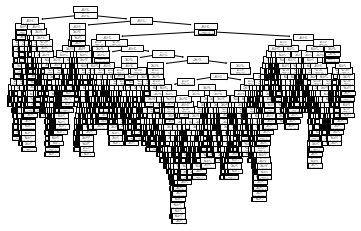

In [26]:
tree.plot_tree(tree_clf[19]) 



In [28]:
label = data.drop(['type'], axis=1)
get_code(clf, label.columns)

if ( Vendor <= 1.5 ) {
if ( Vendor <= 0.5 ) {
return [[13.  0.  0.  0.  0.]]
} else {
return [[ 0.  0.  0.  0. 42.]]
}
} else {
if ( Vendor <= 3.5 ) {
return [[ 0.  0. 24.  0.  0.]]
} else {
if ( open_port <= 0.5 ) {
if ( Vendor <= 7.5 ) {
return [[0. 0. 8. 0. 0.]]
} else {
if ( Vendor <= 12.0 ) {
return [[ 0.  0.  0. 17.  0.]]
} else {
return [[0. 0. 7. 0. 0.]]
}
}
} else {
if ( Vendor <= 7.5 ) {
if ( Vendor <= 4.5 ) {
return [[ 0. 12.  0.  0.  0.]]
} else {
return [[19.  0.  0.  0.  0.]]
}
} else {
if ( open_port <= 1.5 ) {
if ( Vendor <= 9.5 ) {
return [[0. 8. 0. 0. 0.]]
} else {
return [[ 0.  0.  0.  0. 11.]]
}
} else {
if ( Vendor <= 13.5 ) {
return [[ 0. 37.  0.  0.  0.]]
} else {
if ( DNS <= 137.5 ) {
if ( DNS <= 64.5 ) {
if ( DNS <= 33.0 ) {
if ( DNS <= 7.5 ) {
return [[0. 0. 0. 1. 0.]]
} else {
if ( DNS <= 28.5 ) {
if ( DNS <= 20.5 ) {
if ( DNS <= 14.5 ) {
return [[0. 1. 0. 1. 0.]]
} else {
return [[0. 1. 0. 1. 0.]]
}
} else {
if ( DNS <= 26.5 ) {
return [[0. 1. 0. 0. 0.]]
} e